# Praktikum Week 9 Mata Kuliah Kecerdasan Buatan
## Materi: Artificial Neural Network (ANN) - Image Classification
**Dataset:** Sign Language MNIST (Klasifikasi Bahasa Isyarat Amerika / ASL)

### 1. Instalasi dan Import Library

**Penjelasan & Kegunaan:**
Pada tahap ini, Menyiapkan pustaka (*libraries*) yang dibutuhkan:
* **Pandas:** Digunakan untuk membaca dataset dari file eksternal berformat `.csv` ke dalam struktur data *DataFrame*.
* **NumPy:** Memfasilitasi manipulasi array multidimensi dan operasi komputasi numerik secara efisien.
* **Matplotlib (`pyplot`):** Pustaka visualisasi data untuk menampilkan gambar citra piksel serta grafik kurva performa model.
* **TensorFlow & Keras:** Kerangka kerja (*framework*) utama untuk membangun, melatih, mengevaluasi, dan menguji arsitektur *Artificial Neural Network* (ANN).

In [2]:
%pip install tensorflow

   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 2.6/384.1 MB 16.1 MB/s eta 0:00:24
    --------------------------------------- 7.6/384.1 MB 20.3 MB/s eta 0:00:19
   - -------------------------------------- 12.6/384.1 MB 21.3 MB/s eta 0:00:18
   - -------------------------------------- 18.6/384.1 MB 23.2 MB/s eta 0:00:16
   -- ------------------------------------- 22.3/384.1 MB 21.9 MB/s eta 0:00:17
   -- ------------------------------------- 25.7/384.1 MB 21.1 MB/s eta 0:00:18
   --- ------------------------------------ 30.4/384.1 MB 21.2 MB/s eta 0:00:17
   --- ------------------------------------ 35.7/384.1 MB 21.6 MB/s eta 0:00:17
   ---- ----------------------------------- 38.8/384.1 MB 20.8 MB/s eta 0:00:17
   ---- ----------------------------------- 43.8/384.1 MB 21.0 MB/s eta 0:00:17
   ---- ----------------------------------- 46.7/384.1 MB 20.4 MB/s eta 0:00:17
   ----- ---------------------------------- 51.4/38

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# Import library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Input

print(f"TensorFlow Version: {tf.__version__}")

TensorFlow Version: 2.22.0-rc0


### 2. Memuat Dataset, Reshaping, dan Normalisasi Data

**Penjelasan & Kegunaan:**
1. **Pemisahan Fitur & Label:** Dataset `sign_mnist_train.csv` dan `sign_mnist_test.csv` memiliki kolom pertama bernama `label` (target kelas berupa angka 0–24), sedangkan 784 kolom sisanya adalah intensitas piksel citra. Kita pisahkan kolom label dari nilai pikselnya.
2. **Reshaping:** Karena citra disimpan dalam format datar 1D (784 kolom), kita ubah (*reshape*) kembali menjadi matriks citra 2D berukuran $28 \times 28$ piksel agar sesuai dengan dimensi citra aslinya.
3. **Normalisasi Piksel:** Nilai intensitas piksel mentah berada pada rentang $0$ hingga $255$. Dengan membaginya dengan `255.0`, rentang diubah menjadi $[0, 1]$. Normalisasi ini krusial agar proses optimasi matematis (*gradient descent*) berjalan stabil, cepat mencapai konvergensi, dan mencegah masalah gradien meledak (*exploding gradient*).

In [4]:
# 1. Membaca dataset CSV 
print("Sedang memuat data...")
train_df = pd.read_csv('sign_mnist_train.csv')
test_df = pd.read_csv('sign_mnist_test.csv')

# 2. Memisahkan target label dengan data piksel
train_labels = train_df['label'].values
train_images = train_df.drop('label', axis=1).values

test_labels = test_df['label'].values
test_images = test_df.drop('label', axis=1).values

# 3. Mengubah bentuk vektor 784 kolom menjadi format gambar 28x28 piksel
train_images = train_images.reshape(-1, 28, 28)
test_images = test_images.reshape(-1, 28, 28)

# 4. Normalisasi nilai piksel ke rentang [0, 1]
train_images = train_images / 255.0
test_images = test_images / 255.0

print(f"Data latih : {train_images.shape[0]} sampel (dimensi: {train_images.shape[1:]})")
print(f"Data uji   : {test_images.shape[0]} sampel (dimensi: {test_images.shape[1:]})")

Sedang memuat data...
Data latih : 27455 sampel (dimensi: (28, 28))
Data uji   : 7172 sampel (dimensi: (28, 28))


### 3. Eksplorasi & Visualisasi Data Sampel

**Penjelasan & Kegunaan:**
Sebelum melatih model, langkah *Exploratory Data Analysis* (EDA) visual diperlukan untuk memastikan data citra telah terkonversi dengan benar (tidak terbalik atau rusak) serta mencocokkan tampilan visual tangan dengan label kelas yang tertera.

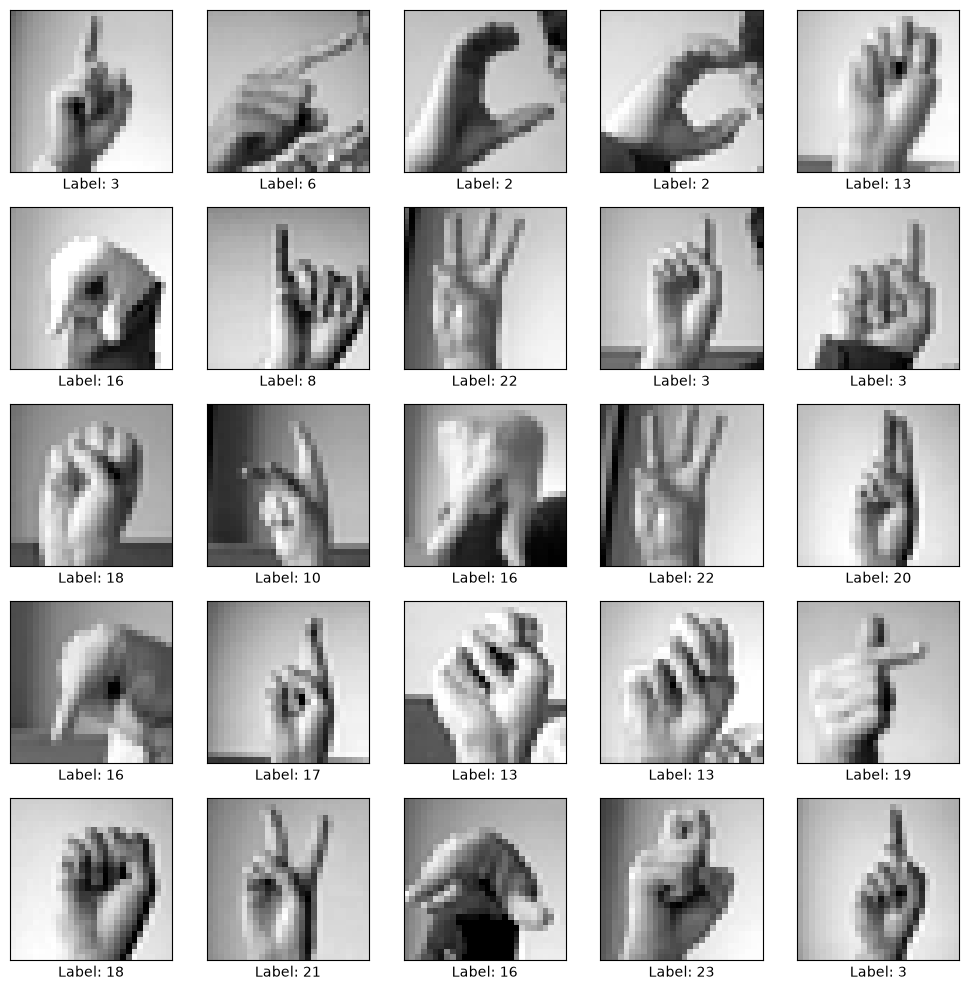

In [5]:
# Menampilkan 25 sampel gambar pertama dari data latih
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i], cmap='gray')
    plt.xlabel(f"Label: {train_labels[i]}")
plt.tight_layout()
plt.show()

### 4. Membangun Arsitektur Artificial Neural Network (ANN)

**Penjelasan & Kegunaan:**
Membangun model jaringan saraf tiruan bertipe *Multilayer Perceptron (MLP) Feedforward* secara sekuensial:
1. **`Input(shape=(28, 28))`:** Menentukan dimensi matriks masukan secara eksplisit.
2. **`Flatten()`:** Meratakan matriks 2D $28 \times 28$ menjadi vektor linear 1D berisi 784 elemen agar dapat diterima oleh neuron *Fully Connected*.
3. **`Dense(128, activation='relu')`:** *Hidden layer* dengan 128 neuron. Fungsi aktivasi **ReLU** (*Rectified Linear Unit*) memberikan sifat non-linear sehingga model mampu mempelajari pola visual yang kompleks.
4. **`Dense(num_classes, activation='softmax')`:** *Output layer*. Fungsi aktivasi **Softmax** mengubah keluaran mentah (*logits*) menjadi distribusi probabilitas di mana total seluruh kelas bernilai 1. Kelas dengan nilai probabilitas tertinggi dipilih sebagai hasil klasifikasi akhir.

In [6]:
# Menghitung jumlah kelas unik yang ada
num_classes = int(max(train_labels.max(), test_labels.max())) + 1

# Membangun arsitektur model
model = Sequential([
    Input(shape=(28, 28)),                  # Layer input (28x28 piksel)
    Flatten(),                              # Layer flattening (784 input)
    Dense(128, activation='relu'),          # Hidden layer dengan 128 neuron
    Dense(num_classes, activation='softmax') # Output layer dengan aktivasi Softmax
])

# Menampilkan ringkasan parameter arsitektur model
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 25)             │         3,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 103,705 (405.10 KB)

 Trainable params: 103,705 (405.10 KB)

 Non-trainable params: 0 (0.00 B)

### 5. Kompilasi dan Melatih Model (Training)

**Penjelasan & Kegunaan:**
* **Optimizer (`adam`):** Algoritma optimasi yang secara adaptif memperbarui bobot (*weights*) dan bias berdasarkan gradien saat proses *backpropagation*.
* **Loss Function (`sparse_categorical_crossentropy`):** Fungsi kerugian untuk masalah klasifikasi multi-kelas dengan target label berbentuk bilangan bulat (*integer*, misal: 0, 1, 2, ...).
* **Metrics (`accuracy`):** Metrik untuk mengukur rasio ketepatan prediksi model terhadap data sebenarnya.
* **`model.fit()`:** Proses iterasi pembelajaran selama 10 kali putaran penuh (*epochs*), menggunakan data validasi untuk memantau performa model secara langsung pada data uji di setiap epoch.

In [7]:
# Kompilasi konfigurasi pembelajaran model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Melatih model
history = model.fit(
    train_images, 
    train_labels, 
    epochs=10, 
    validation_data=(test_images, test_labels)
)

Epoch 1/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.3906 - loss: 2.1033 - val_accuracy: 0.5093 - val_loss: 1.6581
Epoch 2/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6431 - loss: 1.2220 - val_accuracy: 0.5871 - val_loss: 1.3414
Epoch 3/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7346 - loss: 0.9119 - val_accuracy: 0.6253 - val_loss: 1.1960
Epoch 4/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7926 - loss: 0.7261 - val_accuracy: 0.6525 - val_loss: 1.1167
Epoch 5/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8294 - loss: 0.5966 - val_accuracy: 0.6636 - val_loss: 1.0721
Epoch 6/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8597 - loss: 0.4972 - val_accuracy: 0.6728 - val_loss: 1.0455
Epoch 7/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8843 - loss: 0.4163 - val_accuracy: 0.6942 - val_loss: 1.0212
Epoch 8/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9061 - loss: 0.3456 - val_accuracy: 0.

### 6. Evaluasi Model pada Data Uji

**Penjelasan & Kegunaan:**
Langkah ini digunakan untuk mengukur kinerja generalisasi akhir model pada sekumpulan data yang benar-benar baru (*unseen data*). Pengujian ini memastikan model tidak hanya menghafal data latih, melainkan benar-benar memahami pola gestur tangan.

In [8]:
# Evaluasi performa model menggunakan data pengujian
test_loss, test_acc = model.evaluate(test_images, test_labels)

print(f'\nTest Loss    : {test_loss:.4f}')
print(f'Test Accuracy: {test_acc:.4f}')

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7178 - loss: 1.0179

Test Loss    : 1.0179
Test Accuracy: 0.7178


### 7. Visualisasi Kurva Akurasi dan Loss (Plot History)

**Penjelasan & Kegunaan:**
* **Kurva Akurasi:** Memvisualisasikan kenaikan ketepatan model dari epoch ke epoch.
* **Kurva Loss:** Memvisualisasikan penurunan nilai kesalahan (*error*).
* **Analisis Overfitting:** Jika kurva *Training Loss* terus menurun sementara *Validation Loss* mulai berbalik naik atau stagnan, ini merupakan indikasi adanya kondisi *overfitting* (model terlalu menghafal data latih).

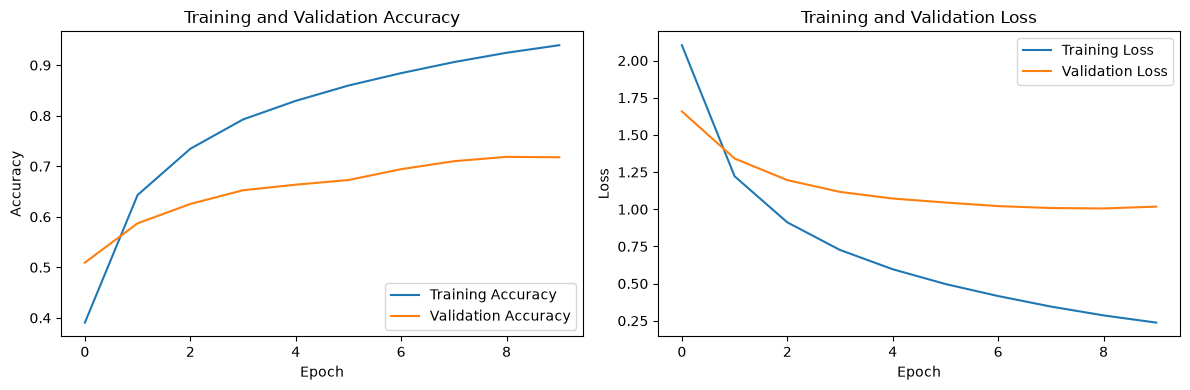

In [9]:
# Membuat fungsi untuk visualisasi kurva evaluasi
def plot_history(hist):
    plt.figure(figsize=(12, 4))

    # Grafik Akurasi
    plt.subplot(1, 2, 1)
    plt.plot(hist.history['accuracy'], label='Training Accuracy')
    plt.plot(hist.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')

    # Grafik Loss
    plt.subplot(1, 2, 2)
    plt.plot(hist.history['loss'], label='Training Loss')
    plt.plot(hist.history['val_loss'], label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')

    plt.tight_layout()
    plt.show()

# Menampilkan grafik
plot_history(history)

### 8. Inferensi Prediksi pada Sampel Data Uji

**Penjelasan & Kegunaan:**
1. **`model.predict()`:** Menghitung vektor nilai probabilitas untuk setiap kelas target dari data uji.
2. **`np.argmax()`:** Memilih indeks kelas dengan nilai probabilitas tertinggi sebagai hasil tebakan model.
3. **Visualisasi Hasil:** Menampilkan 25 gambar pertama dari data uji dengan keterangan teks:
   * **Biru:** Model memprediksi dengan **tepat** sesuai label asli.
   * **Merah:** Model melakukan **kesalahan** prediksi.

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


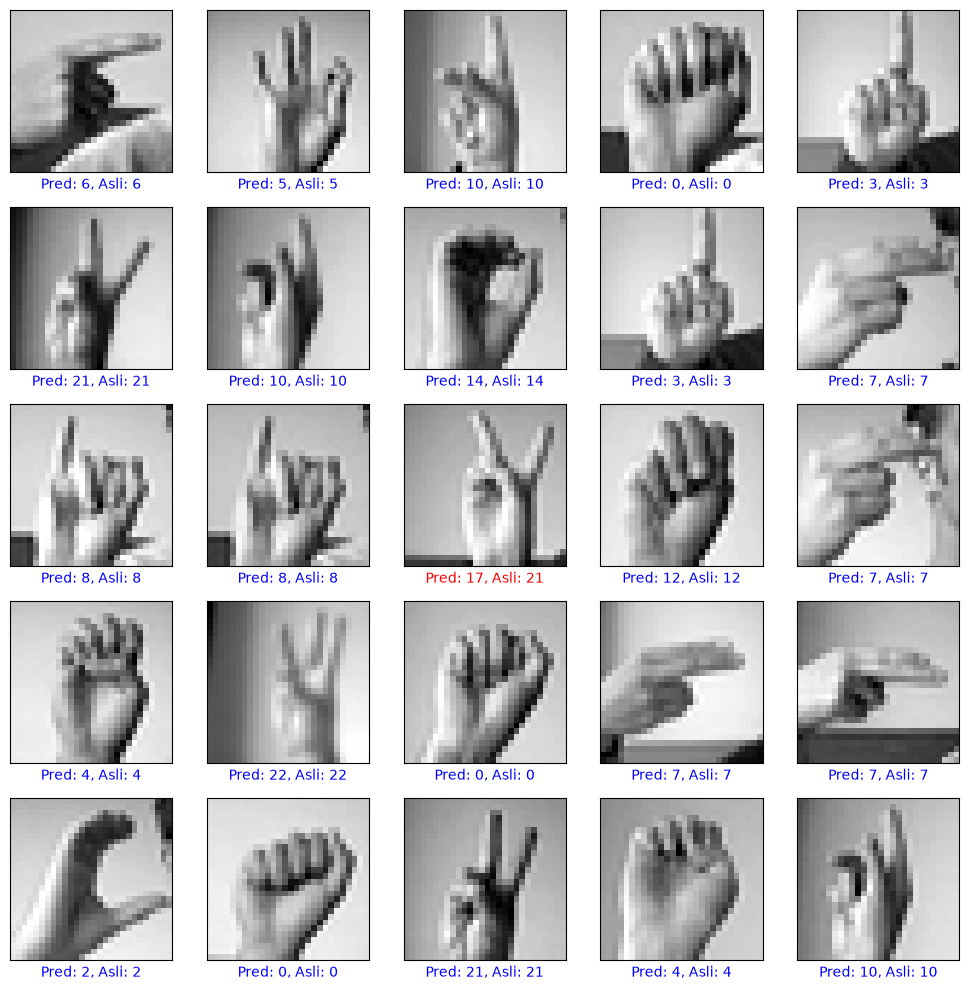

In [10]:
# Melakukan prediksi probabilitas pada seluruh data uji
predictions = model.predict(test_images)

# Visualisasi 25 gambar uji beserta perbandingan prediksi vs label asli
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(test_images[i], cmap='gray')
    
    predicted_label = np.argmax(predictions[i])
    actual_label = test_labels[i]
    
    # Warna biru jika benar, merah jika salah
    color = 'blue' if predicted_label == actual_label else 'red'
    plt.xlabel(f"Pred: {predicted_label}, Asli: {actual_label}", color=color)

plt.tight_layout()
plt.show()